In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import io
import tarfile
import urllib
from pathlib import Path
from PIL import Image
import shutil
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
URL = "https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz"
ARCHIVE_PATH = Path("BSR_bsds500.tgz")
OUTPUT_DIR = Path("BSD500_landscape")
SPLITS = ("train", "test")

In [ ]:
print("Sťahujem BSD500...")
request = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(request) as response:
    with ARCHIVE_PATH.open("wb") as output:
        shutil.copyfileobj(response, output)

print(f"\nArchív bol uložený do: {ARCHIVE_PATH}")

Sťahujem BSD500...

Archív bol uložený do: BSR_bsds500.tgz


In [ ]:
counts = {split: 0 for split in SPLITS}
for split in SPLITS:
    (OUTPUT_DIR / split).mkdir(parents=True, exist_ok=True)

print("Vyberáme obrázky orientované na šírku...")
with tarfile.open(ARCHIVE_PATH, mode="r:gz") as archive:
    for member in archive.getmembers():
        if not member.isfile():
            continue

        path = Path(member.name)
        split = path.parent.name
        if split not in SPLITS:
            continue

        if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        source = archive.extractfile(member)
        if source is None:
            continue

        image_data = source.read()
        with Image.open(io.BytesIO(image_data)) as image:
            width, height = image.size

        if width > height:
            destination = OUTPUT_DIR / split / path.name
            destination.write_bytes(image_data)

            counts[split] += 1

print(f"Dataset uložený do: {OUTPUT_DIR.resolve()}",end="")
for split in SPLITS:
    print(f" {split:5s}: {counts[split]},",end="")

print(f" rozlíšenie: {width} x {height}")

Vyberáme obrázky orientované na šírku...
Dataset uložený do: /content/BSD500_landscape train: 137, test : 134, 481 x 321


In [ ]:
class DenoisingDataset(Dataset):
    def __init__(
        self,
        image_directory,
        sigma_min=5.0,
        sigma_max=50.0
    ):
        image_paths = sorted(path for path in Path(image_directory).iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"})
        self.sigma_min = sigma_min
        self.sigma_max = sigma_max
        images = []
        for image_path in image_paths:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                images.append(np.asarray(image, dtype=np.uint8))

        self.images = np.stack(images) # (N, H, W, C)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        # NumPy uint8 (H, W, C) -> PyTorch float32 (C, H, W)
        clean_image = torch.from_numpy(self.images[index]).permute(2, 0, 1).float() / 255.0
        sigma = torch.empty(1).uniform_(self.sigma_min, self.sigma_max).item() / 255.0
        noise = torch.randn(clean_image.shape, dtype=clean_image.dtype) * sigma
        noisy_image = torch.clamp(clean_image + noise, min=0.0, max=1.0)
        return noisy_image, clean_image

In [ ]:
train_dataset = DenoisingDataset("BSD500_landscape/train", sigma_min=5, sigma_max=50)
test_dataset = DenoisingDataset("BSD500_landscape/test", sigma_min=25, sigma_max=25)

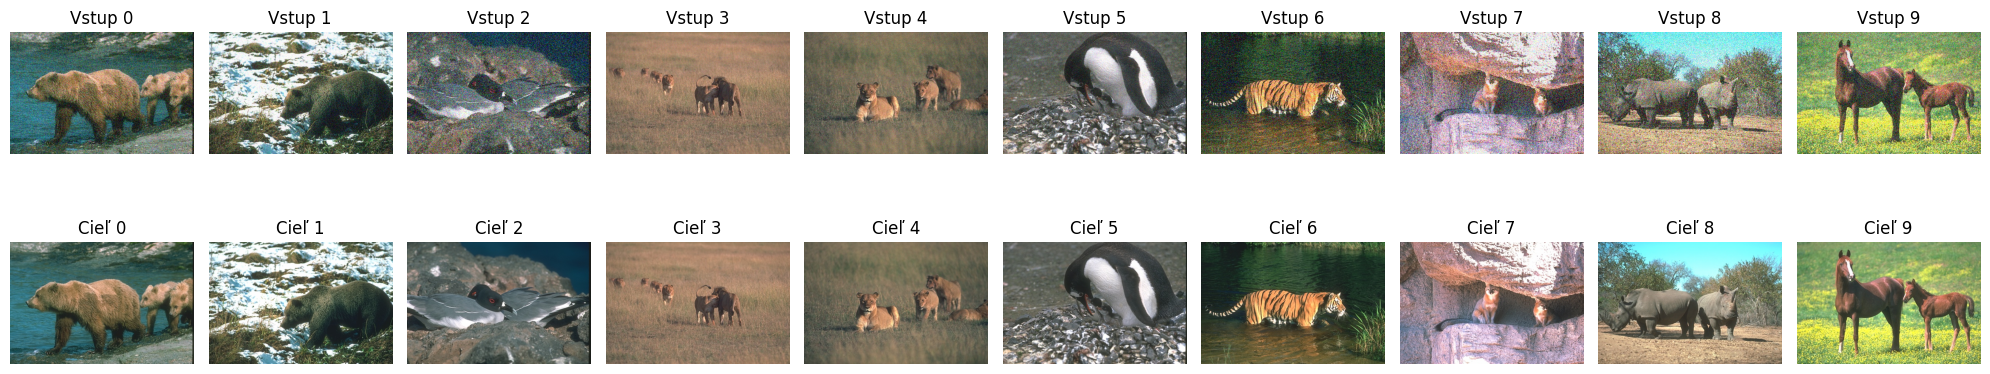

In [ ]:
offset = 0
fig, axes = plt.subplots(2, 10, figsize=(20, 5))
for i in range(10):
    noisy_image, clean_image = train_dataset[i+offset]

    # (C, H, W) -> (H, W, C)
    noisy_image = noisy_image.permute(1, 2, 0).numpy()
    clean_image = clean_image.permute(1, 2, 0).numpy()

    axes[0, i].imshow(noisy_image)
    axes[0, i].set_title(f"Vstup {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(clean_image)
    axes[1, i].set_title(f"Cieľ {i}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [ ]:
class DenoisingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 3, kernel_size=3, padding=1),
            #nn.Sigmoid()
        )

    def forward(self, x):
        return torch.clamp(self.net(x), min=0.0, max=1.0)

In [ ]:
model = DenoisingCNN()

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
model.to(device)

DenoisingCNN(
  (net): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam (model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

number_of_epochs = 100
best_test_loss = float("inf")

train_losses = []
test_losses = []
test_psnr_values = []

for epoch in range(1, number_of_epochs + 1):
    model.train()

    total_train_loss = 0.0
    number_of_train_images = 0

    for noisy_images, clean_images in train_loader:
        noisy_images = noisy_images.to(device)
        clean_images = clean_images.to(device)

        optimizer.zero_grad()

        predicted_images = model(noisy_images)

        loss = criterion(predicted_images, clean_images)

        loss.backward()
        optimizer.step()

        batch_size = noisy_images.shape[0]
        total_train_loss += loss.item() * batch_size
        number_of_train_images += batch_size

    average_train_loss = total_train_loss / number_of_train_images

    model.eval()

    total_test_loss = 0.0
    number_of_test_images = 0

    with torch.no_grad():
        for noisy_images, clean_images in test_loader:
            noisy_images = noisy_images.to(device)
            clean_images = clean_images.to(device)

            predicted_images = model(noisy_images)

            loss = criterion(predicted_images, clean_images)

            batch_size = noisy_images.shape[0]
            total_test_loss += loss.item() * batch_size
            number_of_test_images += batch_size

    average_test_loss = total_test_loss / number_of_test_images

    scheduler.step(average_test_loss)

    train_losses.append(average_train_loss)
    test_losses.append(average_test_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    if average_test_loss < best_test_loss:
        best_test_loss = average_test_loss
        torch.save(model, "denoising_model_best.pth")
        saved = True
    else:
        saved = False

    print(
        f"Epoch {epoch:3d}/{number_of_epochs} | "
        f"train MSE: {average_train_loss:.6f} | "
        f"test MSE: {average_test_loss:.6f} | "
        f"LR: {current_lr:.2e}"
        f" {'saved' if saved else ''}"
    )

Epoch   1/100 | train MSE: 0.055333 | test MSE: 0.022607 | LR: 1.00e-03 saved
Epoch   2/100 | train MSE: 0.014729 | test MSE: 0.010208 | LR: 1.00e-03 saved
Epoch   3/100 | train MSE: 0.007982 | test MSE: 0.006038 | LR: 1.00e-03 saved
Epoch   4/100 | train MSE: 0.005623 | test MSE: 0.005244 | LR: 1.00e-03 saved
Epoch   5/100 | train MSE: 0.004589 | test MSE: 0.004074 | LR: 1.00e-03 saved
Epoch   6/100 | train MSE: 0.003904 | test MSE: 0.003366 | LR: 1.00e-03 saved
Epoch   7/100 | train MSE: 0.003349 | test MSE: 0.003258 | LR: 1.00e-03 saved
Epoch   8/100 | train MSE: 0.003127 | test MSE: 0.002777 | LR: 1.00e-03 saved
Epoch   9/100 | train MSE: 0.002863 | test MSE: 0.002773 | LR: 1.00e-03 saved
Epoch  10/100 | train MSE: 0.002762 | test MSE: 0.002471 | LR: 1.00e-03 saved
Epoch  11/100 | train MSE: 0.002526 | test MSE: 0.002333 | LR: 1.00e-03 saved
Epoch  12/100 | train MSE: 0.002560 | test MSE: 0.002324 | LR: 1.00e-03 saved
Epoch  13/100 | train MSE: 0.002384 | test MSE: 0.002130 | LR: 1

In [ ]:
model = torch.load('denoising_model_best.pth',weights_only=False)

In [ ]:
def psnr(predicted, target): # Peak Signal-to-Noise Ratio, pomer špičkovej hodnoty signálu k šumu
    mse = torch.mean((predicted - target) ** 2)
    dB = 10 * torch.log10(1.0 / (mse + 1e-7))
    return dB.item()

20 dB -> 31 dB
20 dB -> 27 dB
20 dB -> 31 dB
20 dB -> 31 dB
21 dB -> 27 dB
20 dB -> 26 dB
20 dB -> 28 dB
20 dB -> 32 dB
20 dB -> 29 dB
20 dB -> 30 dB


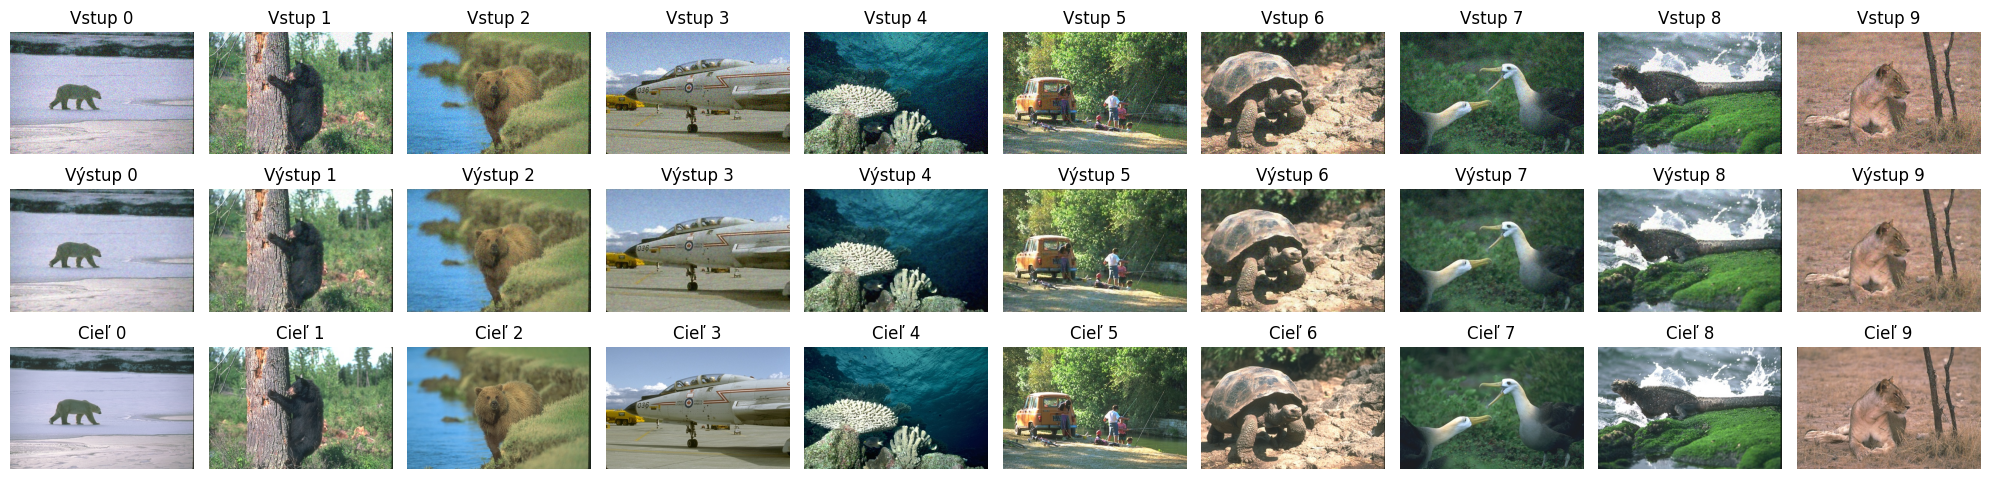

In [ ]:
offset = 0
fig, axes = plt.subplots(3, 10, figsize=(20, 5))
for i in range(10):
    noisy_image, clean_image = test_dataset[i+offset]

    noisy_image_blob = noisy_image.unsqueeze(0).to(device)
    with torch.no_grad():
        predicted_image = model(noisy_image_blob)[0].cpu()

    print(f"{psnr(noisy_image, clean_image):.0f} dB -> {psnr(predicted_image, clean_image):.0f} dB")

    # (C, H, W) -> (H, W, C)
    noisy_image = noisy_image.permute(1, 2, 0).numpy()
    clean_image = clean_image.permute(1, 2, 0).numpy()
    predicted_image = predicted_image.permute(1, 2, 0).numpy()

    axes[0, i].imshow(noisy_image)
    axes[0, i].set_title(f"Vstup {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(predicted_image)
    axes[1, i].set_title(f"Výstup {i}")
    axes[1, i].axis("off")

    axes[2, i].imshow(clean_image)
    axes[2, i].set_title(f"Cieľ {i}")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()